In [1]:
pip install numpy pandas matplotlib scikit-learn

PERFORMANCE EVALUATION OF REGRESSION MODELS
Application: Diabetes Disease Progression Prediction
Dataset records: 442
Input features: 10
Features: age, sex, bmi, bp, s1, s2, s3, s4, s5, s6
Target: quantitative measure of disease progression one year after baseline

Training records: 353
Testing records: 89

MODEL PERFORMANCE COMPARISON
(Lower error is better; higher R2 is better)

                       Model    MAE      MSE   RMSE R2 Score Training + prediction time (s)
           Gradient Boosting 42.549 2727.244 52.223    0.485                        0.43178
               Random Forest 43.274 2860.393 53.483    0.460                        1.08481
Linear Regression (Batch GD) 42.795 2899.856 53.850    0.453                        0.18722
           Linear Regression 42.794 2900.194 53.853    0.453                        0.04739
               Decision Tree 47.045 3568.965 59.741    0.326                        0.01507

Best model by test RMSE: Gradient Boosting

FIRST 10 TEST PREDI

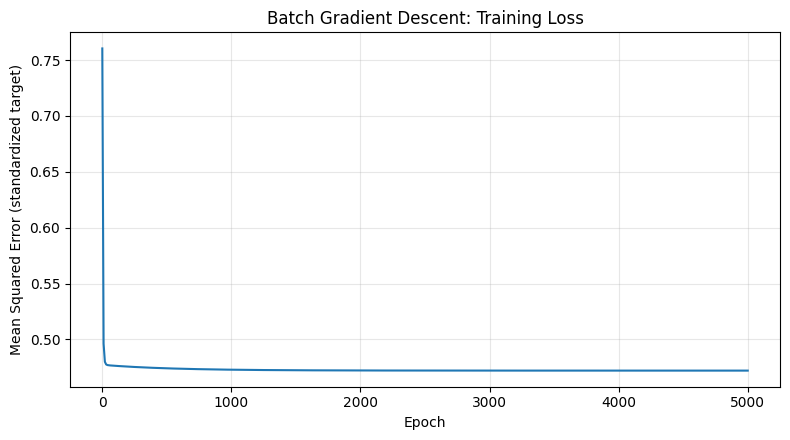

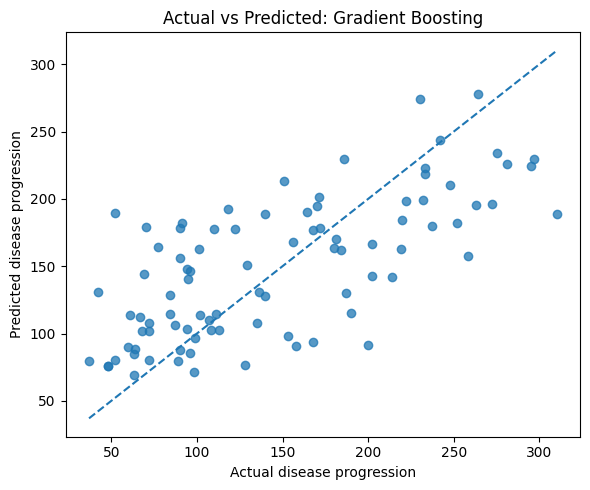


Saved graph: gradient_descent_loss.png
Saved graph: actual_vs_predicted.png
Saved table: regression_model_metrics.csv


In [2]:
# ============================================================
# Application: Diabetes Disease Progression Prediction
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ------------------------------------------------------------
# 1. Evaluation Metrics
# ------------------------------------------------------------

def regression_metrics(y_true, y_pred):
    """Calculate common regression evaluation metrics."""

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }


# ------------------------------------------------------------
# 2. Batch Gradient Descent Implementation
# ------------------------------------------------------------

def batch_gradient_descent(
    X, y, learning_rate=0.05, epochs=5000
):
    """
    Train Linear Regression using Batch Gradient Descent.
    """

    # Standardize input features
    x_scaler = StandardScaler()
    X_scaled = x_scaler.fit_transform(X)

    # Standardize target variable
    y_scaler = StandardScaler()
    y_scaled = y_scaler.fit_transform(
        np.asarray(y).reshape(-1, 1)
    ).ravel()

    n_samples, n_features = X_scaled.shape

    # Initialize weights and bias
    weights = np.zeros(n_features, dtype=float)
    bias = 0.0

    losses = []
    loss_epochs = []

    # Batch Gradient Descent
    for epoch in range(epochs):

        # Calculate predictions
        predictions = X_scaled @ weights + bias

        # Calculate prediction errors
        errors = predictions - y_scaled

        # Calculate gradients
        dw = (2 / n_samples) * (X_scaled.T @ errors)
        db = (2 / n_samples) * np.sum(errors)

        # Update weights and bias
        weights -= learning_rate * dw
        bias -= learning_rate * db

        # Store loss periodically
        if epoch % 10 == 0 or epoch == epochs - 1:

            updated_predictions = X_scaled @ weights + bias

            loss = np.mean(
                (updated_predictions - y_scaled) ** 2
            )

            losses.append(loss)
            loss_epochs.append(epoch + 1)

    return (
        x_scaler,
        y_scaler,
        weights,
        bias,
        losses,
        loss_epochs
    )


# ------------------------------------------------------------
# 3. Predict Using the Gradient Descent Model
# ------------------------------------------------------------

def gradient_descent_predict(
    X, x_scaler, y_scaler, weights, bias
):
    """Generate predictions on the original target scale."""

    X_scaled = x_scaler.transform(X)

    predicted_scaled = X_scaled @ weights + bias

    predictions = y_scaler.inverse_transform(
        predicted_scaled.reshape(-1, 1)
    ).ravel()

    return predictions


# ------------------------------------------------------------
# 4. Main Program
# ------------------------------------------------------------

def main():

    # Load the dataset
    dataset = load_diabetes(as_frame=True)

    X = dataset.data
    y = dataset.target

    print("=" * 72)
    print("PERFORMANCE EVALUATION OF REGRESSION MODELS")
    print("Application: Diabetes Disease Progression Prediction")
    print("=" * 72)

    print("Dataset records:", X.shape[0])
    print("Input features:", X.shape[1])
    print("Features:", ", ".join(X.columns))

    print(
        "Target: quantitative measure of disease progression "
        "one year after baseline"
    )

    # --------------------------------------------------------
    # Train-Test Split
    # --------------------------------------------------------

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    print("\nTraining records:", len(X_train))
    print("Testing records:", len(X_test))

    # --------------------------------------------------------
    # Define Standard Regression Models
    # --------------------------------------------------------

    models = {

        "Linear Regression": make_pipeline(
            StandardScaler(),
            LinearRegression()
        ),

        "Decision Tree": DecisionTreeRegressor(
            max_depth=4,
            random_state=42
        ),

        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=5,
            random_state=42
        ),

        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=150,
            learning_rate=0.04,
            max_depth=2,
            random_state=42
        )
    }

    rows = []
    predictions_by_model = {}

    # --------------------------------------------------------
    # Train and Evaluate the Standard Models
    # --------------------------------------------------------

    for name, model in models.items():

        start_time = time.perf_counter()

        # Train the model
        model.fit(X_train, y_train)

        # Make test predictions
        y_pred = model.predict(X_test)

        elapsed_time = time.perf_counter() - start_time

        # Calculate metrics
        metrics = regression_metrics(y_test, y_pred)

        metrics["Model"] = name
        metrics["Training + prediction time (s)"] = elapsed_time

        rows.append(metrics)
        predictions_by_model[name] = y_pred

    # --------------------------------------------------------
    # Train the Manual Batch Gradient Descent Model
    # --------------------------------------------------------

    start_time = time.perf_counter()

    (
        x_scaler,
        y_scaler,
        weights,
        bias,
        losses,
        loss_epochs
    ) = batch_gradient_descent(
        X_train.to_numpy(),
        y_train.to_numpy(),
        learning_rate=0.05,
        epochs=5000
    )

    training_time = time.perf_counter() - start_time

    # Generate test predictions
    start_time = time.perf_counter()

    gd_pred = gradient_descent_predict(
        X_test.to_numpy(),
        x_scaler,
        y_scaler,
        weights,
        bias
    )

    prediction_time = time.perf_counter() - start_time

    gd_metrics = regression_metrics(y_test, gd_pred)

    gd_metrics["Model"] = "Linear Regression (Batch GD)"

    gd_metrics["Training + prediction time (s)"] = (
        training_time + prediction_time
    )

    rows.append(gd_metrics)

    predictions_by_model["Linear Regression (Batch GD)"] = gd_pred

    # --------------------------------------------------------
    # Display Model Comparison
    # --------------------------------------------------------

    results = pd.DataFrame(rows)

    results = results[
        [
            "Model",
            "MAE",
            "MSE",
            "RMSE",
            "R2 Score",
            "Training + prediction time (s)"
        ]
    ]

    results = results.sort_values("RMSE")

    print("\nMODEL PERFORMANCE COMPARISON")
    print("(Lower error is better; higher R2 is better)\n")

    print(
        results.to_string(
            index=False,
            formatters={
                "MAE": "{:.3f}".format,
                "MSE": "{:.3f}".format,
                "RMSE": "{:.3f}".format,
                "R2 Score": "{:.3f}".format,
                "Training + prediction time (s)": "{:.5f}".format
            }
        )
    )

    # --------------------------------------------------------
    # Display Sample Test Predictions
    # --------------------------------------------------------

    best_model_name = results.iloc[0]["Model"]

    best_predictions = predictions_by_model[best_model_name]

    sample = pd.DataFrame({
        "Actual target": y_test.to_numpy()[:10],
        "Predicted target": best_predictions[:10]
    })

    sample["Absolute error"] = np.abs(
        sample["Actual target"] - sample["Predicted target"]
    )

    print("\nBest model by test RMSE:", best_model_name)

    print("\nFIRST 10 TEST PREDICTIONS")

    print(
        sample.to_string(
            index=False,
            formatters={
                "Actual target": "{:.2f}".format,
                "Predicted target": "{:.2f}".format,
                "Absolute error": "{:.2f}".format
            }
        )
    )

    # --------------------------------------------------------
    # Plot 1: Gradient Descent Training Loss
    # --------------------------------------------------------

    plt.figure(figsize=(8, 4.5))

    plt.plot(loss_epochs, losses)

    plt.title("Batch Gradient Descent: Training Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Mean Squared Error (standardized target)")

    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig("gradient_descent_loss.png", dpi=150)

    plt.show()

    # --------------------------------------------------------
    # Plot 2: Actual vs Predicted Values
    # --------------------------------------------------------

    plt.figure(figsize=(6, 5))

    plt.scatter(
        y_test,
        best_predictions,
        alpha=0.75
    )

    lower = min(
        float(y_test.min()),
        float(np.min(best_predictions))
    )

    upper = max(
        float(y_test.max()),
        float(np.max(best_predictions))
    )

    # Ideal prediction reference line
    plt.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--"
    )

    plt.title(f"Actual vs Predicted: {best_model_name}")
    plt.xlabel("Actual disease progression")
    plt.ylabel("Predicted disease progression")

    plt.tight_layout()

    plt.savefig("actual_vs_predicted.png", dpi=150)

    plt.show()

    # --------------------------------------------------------
    # Save the Evaluation Results
    # --------------------------------------------------------

    results.to_csv(
        "regression_model_metrics.csv",
        index=False
    )

    print("\nSaved graph: gradient_descent_loss.png")
    print("Saved graph: actual_vs_predicted.png")
    print("Saved table: regression_model_metrics.csv")


# ------------------------------------------------------------
# Program Entry Point
# ------------------------------------------------------------

if __name__ == "__main__":
    main()